# Moteurs vectoriels comparés — FAISS, pgvector et Qdrant sur le même corpus

**Navigation** : [Index](README.md) | [<< Précédent](05b-Stockage-Vectoriel-Serveur.ipynb) | [Suite >>](06-KernelMemory-InProcess.ipynb)

Le notebook 05 a codé HNSW à la main ; le 05b a mesuré un serveur Qdrant dédié. Celui-ci pose la
question que tout projet RAG rencontre au moment de choisir son stockage : **que change le moteur,
à données et questions égales ?** Trois architectures coexistent ici :

- **FAISS** — une bibliothèque C appelée depuis Python, sans serveur ni même disque ;
- **pgvector** — une extension de PostgreSQL : les vecteurs vivent dans une vraie base SQL ;
- **Qdrant** — un moteur dédié, servi par son conteneur Docker comme dans le 05b.

Les quatre mesures — rappel, latence, empreinte mémoire, filtrage — sont portées par le **même
jeu de données** que 05/05b : même générateur, même graine, même payload. Le ground truth est
calculé en NumPy, hors de tout moteur : juger un moteur avec la vérité qu'il produirait lui-même
serait circulaire.

## 1. Objectifs et protocole de mesure

**Objectifs d'apprentissage** — à la fin de ce notebook, vous saurez :

1. Charger le même corpus vectorisé dans trois architectures de stockage différentes ;
2. Mesurer un compromis rappel/latence objectif par moteur (exact contre approché, paramètre
   de traversée croissant) ;
3. Mesurer l'empreinte mémoire d'un index — au fichier, à la relation, au répertoire — plutôt
   que la déclarer ;
4. Situer la vraie divergence des moteurs : **où passe le filtre métadonnées** (intégré au scan,
   poussé dans le plan SQL, ou post-filtre à la main) ;
5. Lire un comparatif multi-moteurs sans tomber dans le classement de boutique : chaque
   architecture enseigne un compromis différent.

**Protocole** : 10 000 vecteurs de dimension 128 en 50 grappes, 200 requêtes, k = 10. Le rappel@10
d'une requête est la fraction du top-10 exact (NumPy) qu'elle retrouve ; la latence est la médiane
sur les 200 appels. Le paramètre d'exploration (ef / ef_search / hnsw_ef) balaie la même liste
{8, 16, 32, 64, 128, 256} partout — ce sont les trois noms du même bouton.

In [1]:
import os, time, json, random, subprocess, tempfile, urllib.request
from collections import Counter
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

N_VECTORS = 10_000
DIM = 128
N_CLUSTERS = 50
N_QUERIES = 200
K = 10
EF_VALUES = [8, 16, 32, 64, 128, 256]

# Filtrage metadonnees (meme predicat que 05b, cellule filtrage)
FILTER_SOURCE = "incident"
FILTER_SEVERITE = 3  # >=

# -- disponibilite des trois moteurs, testee honnetement, echec visible --
def try_import(mod):
    try:
        __import__(mod)
        return True
    except Exception as e:
        print(f"[env] import {mod} echoue : {type(e).__name__}: {e}")
        return False

def docker_available():
    try:
        r = subprocess.run(["docker", "info"], capture_output=True, timeout=5)
        return r.returncode == 0
    except Exception:
        return False

faiss_ok = try_import("faiss")
qdrant_ok = try_import("qdrant_client")
pg_driver_ok = try_import("psycopg")
docker_ok = docker_available()
print(f"Moteurs locaux : faiss={faiss_ok}, qdrant_client={qdrant_ok}, "
      f"psycopg={pg_driver_ok}, docker={docker_ok}")
print(f"Parametres : N={N_VECTORS}, dim={DIM}, grappes={N_CLUSTERS}, "
      f"requetes={N_QUERIES}, k={K}, ef={EF_VALUES}")

Moteurs locaux : faiss=True, qdrant_client=True, psycopg=True, docker=True
Parametres : N=10000, dim=128, grappes=50, requetes=200, k=10, ef=[8, 16, 32, 64, 128, 256]


### Lecture du résultat : trois moteurs, un seul protocole

La cellule d'ouverture dit ce que chaque moteur **est**, pas ce qu'il vaut : FAISS importe (une
bibliothèque), qdrant_client importe (un client), psycopg importe et Docker tourne (pgvector
vivra dans un conteneur PostgreSQL). Si l'un manquait, la section correspondante sauterait avec
un message visible — un moteur absent ne se remplace pas par une sortie fabriquée.

In [2]:
# Generation de 10k vecteurs clusterises (50 grappes) avec payload semantique
# -- STRICTEMENT le generateur du 05b (meme graine, meme formes), pour que les
#    mesures des deux carnets soient lisibles l'une contre l'autre.
print(f"Generation de {N_VECTORS} vecteurs en {N_CLUSTERS} clusters (dim={DIM})...")
t0 = time.time()

centers = np.random.randn(N_CLUSTERS, DIM).astype('float32')
centers /= np.linalg.norm(centers, axis=1, keepdims=True)

cluster_ids = np.random.randint(0, N_CLUSTERS, size=N_VECTORS)
noise = 0.1 * np.random.randn(N_VECTORS, DIM).astype('float32')
vectors = centers[cluster_ids] + noise
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)

sources = ["incident", "documentation", "faq", "release_notes"]
payloads = [
    {"id": i, "source": random.choice(sources), "severite": random.randint(1, 5),
     "cluster_id": int(cluster_ids[i])}
    for i in range(N_VECTORS)
]

t1 = time.time()
print(f"Generation : {t1-t0:.2f}s | vectors.shape={vectors.shape}")
print(f"Normes : min={np.linalg.norm(vectors, axis=1).min():.4f}, "
      f"max={np.linalg.norm(vectors, axis=1).max():.4f}")
print(f"Sources : {dict(Counter(p['source'] for p in payloads))}")
print(f"Severites : {dict(sorted(Counter(p['severite'] for p in payloads).items()))}")
mask_filter = np.array([p["source"] == FILTER_SOURCE and p["severite"] >= FILTER_SEVERITE
                        for p in payloads])
print(f"Predicat de filtrage ({FILTER_SOURCE}, severite>={FILTER_SEVERITE}) : "
      f"{mask_filter.sum()}/{N_VECTORS} vecteurs ({100*mask_filter.mean():.1f}%)")

Generation de 10000 vecteurs en 50 clusters (dim=128)...
Generation : 0.10s | vectors.shape=(10000, 128)
Normes : min=1.0000, max=1.0000
Sources : {'incident': 2496, 'faq': 2481, 'documentation': 2478, 'release_notes': 2545}
Severites : {1: 2021, 2: 2073, 3: 1952, 4: 2029, 5: 1925}
Predicat de filtrage (incident, severite>=3) : 1470/10000 vecteurs (14.7%)


### Lecture du résultat : le corpus du 05b, rejoué à l'identique

Mêmes distributions que 05b (sources à peu près équilibrées, sévérités 1 à 5, ~15 % des vecteurs
passent le prédicat de filtrage). Ce n'est pas un détail de reproduction : rappel et latence de
Qdrant mesurés ici doivent pouvoir se lire contre la courbe signature du 05b — si le corpus
dérivait, la comparaison serait fausse dès la génération.

In [3]:
# Ground truth exact en NumPy, hors de tout moteur : version non filtree + version filtree
print(f"Ground truth exact sur {N_QUERIES} requetes, K={K} (non filtre + filtre)...")
t0 = time.time()

query_indices = np.random.choice(N_VECTORS, size=N_QUERIES, replace=False)
queries = vectors[query_indices]

def exact_topk(q, mask=None):
    """Top-K exact par produit scalaire (vecteurs normes = cosinus).
    mask=None : verite non filtree ; mask=bool array : verite APRES le predicat."""
    sims = vectors @ q
    if mask is not None:
        sims = np.where(mask, sims, -np.inf)
    top = np.argpartition(-sims, K)[:K]
    return set(int(i) for i in top[np.argsort(-sims[top])])

gt_plain = [exact_topk(q) for q in queries]
gt_filtered = [exact_topk(q, mask_filter) for q in queries]

t1 = time.time()
print(f"Ground truth : {t1-t0:.2f}s ({2*N_QUERIES/(t1-t0):.1f} verites/s)")
print(f"Recouvrement moyen non-filtre vs filtre : "
      f"{np.mean([len(a & b)/K for a, b in zip(gt_plain, gt_filtered)]):.3f}")
print("Une requete a filtre selectif a un top-10 filtre tres different du top-10 brut : "
      "c'est la divergence que la section 6 mesure.")

Ground truth exact sur 200 requetes, K=10 (non filtre + filtre)...


Ground truth : 0.17s (2382.2 verites/s)
Recouvrement moyen non-filtre vs filtre : 0.146
Une requete a filtre selectif a un top-10 filtre tres different du top-10 brut : c'est la divergence que la section 6 mesure.


### Lecture du résultat : deux vérités, pas une

Le recouvrement entre top-10 brut et top-10 filtré est faible : filtrer change la réponse, pas
seulement le nombre de réponses. Toute la suite juge les moteurs contre **gt_plain** (sections
2-5) puis contre **gt_filtered** (section 6) — deux vérités NumPy, aucune produite par un
moteur.

## 2. FAISS — la bibliothèque, sans serveur ni disque

FAISS (Facebook AI Similarity Search) est une bibliothèque C++ appelée en processus. Deux index :
`IndexFlatIP` (exact : compare la requête à tout le monde, produit scalaire) et `IndexHNSWFlat`
(approché : le même graphe petit-monde que le 05 codait à la main). Le fil de threads est fixé à 1
pour que la latence mesurée soit celle d'un cœur — sinon FAISS parallélise la recherche et la
mesure dépend du nombre de cœurs de la machine.

In [4]:
import faiss
faiss.omp_set_num_threads(1)

faiss_results = []

if faiss_ok:
    # Index exact : produit scalaire brut (vecteurs normes -> cosinus)
    t0 = time.time()
    index_flat = faiss.IndexFlatIP(DIM)
    index_flat.add(vectors)
    t_flat_build = time.time() - t0

    # Index approche : HNSW m=16, ef_construction=100 (meme reglages que le serveur du 05b)
    t0 = time.time()
    index_hnsw = faiss.IndexHNSWFlat(DIM, 16, faiss.METRIC_INNER_PRODUCT)
    index_hnsw.hnsw.efConstruction = 100
    index_hnsw.add(vectors)
    t_hnsw_build = time.time() - t0

    # Empreinte memoire MESUREE : taille du fichier serialise, pas la doc
    tmpdir = tempfile.mkdtemp(prefix="rag05c_faiss_")
    faiss.write_index(index_flat, os.path.join(tmpdir, "flat.faiss"))
    faiss.write_index(index_hnsw, os.path.join(tmpdir, "hnsw.faiss"))
    mem_flat = os.path.getsize(os.path.join(tmpdir, "flat.faiss"))
    mem_hnsw = os.path.getsize(os.path.join(tmpdir, "hnsw.faiss"))

    print(f"FlatIP   : construction {t_flat_build:.2f}s, fichier {mem_flat/1e6:.1f} Mo")
    print(f"HNSW     : construction {t_hnsw_build:.2f}s, fichier {mem_hnsw/1e6:.1f} Mo "
          f"(theorie vecteurs seuls : {N_VECTORS*DIM*4/1e6:.1f} Mo)")

    def bench_faiss(index, tag, ef=None):
        if ef is not None:
            index.hnsw.ef = ef
        recalls, lat = [], []
        for qi, q in enumerate(queries):
            t0 = time.perf_counter()
            _, idx = index.search(q.reshape(1, -1), K)
            lat.append((time.perf_counter() - t0) * 1000)
            recalls.append(len(set(int(i) for i in idx[0]) & gt_plain[qi]) / K)
        row = {"moteur": "FAISS", "mode": tag,
               "recall": float(np.mean(recalls)),
               "latence_med_ms": float(np.median(lat)),
               "latence_p95_ms": float(np.percentile(lat, 95))}
        faiss_results.append(row)
        print(f"  {tag:16s} : recall@10={row['recall']:.3f}, "
              f"mediane={row['latence_med_ms']:.2f} ms, p95={row['latence_p95_ms']:.2f} ms")
        return row

    print("\nBenchmark FAISS (1 thread) :")
    bench_faiss(index_flat, "exact (Flat)")
    for ef in EF_VALUES:
        bench_faiss(index_hnsw, f"hnsw ef={ef}", ef=ef)
else:
    print("FAISS indisponible : section sautee (echec visible, pas de substitution).")

FlatIP   : construction 0.00s, fichier 5.1 Mo
HNSW     : construction 1.20s, fichier 6.6 Mo (theorie vecteurs seuls : 5.1 Mo)

Benchmark FAISS (1 thread) :
  exact (Flat)     : recall@10=1.000, mediane=0.36 ms, p95=0.73 ms
  hnsw ef=8        : recall@10=0.990, mediane=0.05 ms, p95=0.10 ms
  hnsw ef=16       : recall@10=0.990, mediane=0.04 ms, p95=0.06 ms
  hnsw ef=32       : recall@10=0.990, mediane=0.04 ms, p95=0.06 ms
  hnsw ef=64       : recall@10=0.990, mediane=0.04 ms, p95=0.05 ms
  hnsw ef=128      : recall@10=0.990, mediane=0.04 ms, p95=0.05 ms
  hnsw ef=256      : recall@10=0.990, mediane=0.04 ms, p95=0.05 ms


### Lecture du résultat : la latence d'un appel de fonction

Deux faits mesurés, dans cet ordre. D'abord le privilège de la bibliothèque : le Flat exact
descend à 0,4 ms médiane — pas de réseau, pas de sérialisation, pas de planificateur. Ensuite,
sur **ce** corpus, le HNSW est plus rapide que l'exact (0,04 ms) et son rappel reste **plat à
0,990 quel que soit ef** : la rampe rappel/ef du 05b n'apparaît pas, parce que 50 grappes serrées
sont un terrain facile — les 1 % manqués le sont à tous les ef (des points à la frontière de
deux grappes, que le graphe m=16 n'atteint pas), c'est une limite de **graphe**, pas
d'exploration. Le bouton ef redeviendrait décisif sur des données moins structurées. L'empreinte
mesurée confirme l'arithmétique (5,1 Mo de vecteurs nus, 6,6 Mo avec le graphe).

## 3. pgvector — les vecteurs dans une vraie base SQL

pgvector est une extension PostgreSQL : les vecteurs deviennent un type `vector`, l'index HNSW une
vraie relation, et la recherche une requête SQL passée par le planificateur. Le conteneur
(`pgvector/pgvector:pg17`) est provisionné de façon idempotente, comme le serveur Qdrant du 05b —
même pattern, même garde fail-visible.

In [5]:
import psycopg
from pgvector.psycopg import register_vector

PG_CONTAINER = "rag05c_pgvector"
PG_PORT = 5433
PG_DSN = f"host=localhost port={PG_PORT} dbname=rag05c user=postgres password=rag05c"

def pg_ready():
    try:
        with psycopg.connect(PG_DSN, connect_timeout=3, autocommit=True) as c:
            c.execute("SELECT 1")
        return True
    except Exception:
        return False

pg_up = False
if pg_driver_ok and docker_ok:
    if pg_ready():
        pg_up = True
        print(f"pgvector deja joignable sur le port {PG_PORT}.")
    else:
        # port libre ? sinon un autre conteneur le tient deja
        r = subprocess.run(["docker", "ps", "--filter", f"publish={PG_PORT}", "--format", "{{.Names}}"],
                           capture_output=True, timeout=5)
        existing = [n.strip() for n in r.stdout.decode().splitlines() if n.strip()]
        if existing:
            print(f"Port {PG_PORT} occupe par {existing} -- conteneur present mais pas pret, on attend.")
        else:
            print("Lancement du conteneur pgvector (PostgreSQL 17 + extension vector)...")
            subprocess.run(["docker", "rm", "-f", PG_CONTAINER], capture_output=True, timeout=15)
            r = subprocess.run(
                ["docker", "run", "-d", "--rm", "--name", PG_CONTAINER,
                 "-p", f"{PG_PORT}:5432", "-e", "POSTGRES_PASSWORD=rag05c",
                 "-e", "POSTGRES_DB=rag05c", "pgvector/pgvector:pg17"],
                capture_output=True, timeout=60)
            print(f"docker run rc={r.returncode} {r.stdout.decode()[:20]}")
        for _ in range(30):  # attendre le ready
            if pg_ready():
                pg_up = True
                break
            time.sleep(1)
    print(f"pgvector operationnel : {pg_up}")
else:
    print("psycopg ou Docker indisponible : section pgvector sautee (echec visible).")

pg_results = []
if pg_up:
    with psycopg.connect(PG_DSN, autocommit=True) as conn:
        with conn.cursor() as cur:
            # L'extension AVANT l'adaptateur Python : register_vector interroge le
            # catalogue pour le type 'vector', qui n'existe pas avant CREATE EXTENSION.
            cur.execute("CREATE EXTENSION IF NOT EXISTS vector")
            cur.execute("SELECT extversion FROM pg_extension WHERE extname='vector'")
            print(f"Extension vector : v{cur.fetchone()[0]}")
            cur.execute("DROP TABLE IF EXISTS vecs")
            cur.execute("""CREATE TABLE vecs (
                id integer PRIMARY KEY, source text, severite integer,
                cluster_id integer, embedding vector(128))""")
        register_vector(conn)
        # Ingestion par lots : executemany de psycopg3 passe en mode pipeline
        t0 = time.time()
        rows = [(p["id"], p["source"], p["severite"], p["cluster_id"], vectors[i])
                for i, p in enumerate(payloads)]
        with conn.transaction():
            with conn.cursor() as cur:
                cur.executemany(
                    "INSERT INTO vecs (id, source, severite, cluster_id, embedding) "
                    "VALUES (%s, %s, %s, %s, %s)", rows)
        t_pg_insert = time.time() - t0
        # Index HNSW : memes parametres que le serveur Qdrant du 05b (m=16, ef_construction=100)
        t0 = time.time()
        with conn.cursor() as cur:
            cur.execute("CREATE INDEX ON vecs USING hnsw (embedding vector_cosine_ops) "
                        "WITH (m = 16, ef_construction = 100)")
            cur.execute("ANALYZE vecs")
        t_pg_index = time.time() - t0
        with conn.cursor() as cur:
            cur.execute("SELECT pg_size_pretty(pg_total_relation_size('vecs'))")
            total = cur.fetchone()[0]
            cur.execute("SELECT pg_relation_size('vecs_embedding_idx')")
            idx_bytes = cur.fetchone()[0]
            cur.execute("SELECT count(*) FROM vecs")
            cnt = cur.fetchone()[0]
        print(f"Ingestion {cnt} lignes : {t_pg_insert:.2f}s | index HNSW : {t_pg_index:.2f}s")
        print(f"Empreinte MESUREE : index {idx_bytes/1e6:.1f} Mo, relation complete {total}")
        print("Astuce de lecture : pg_relation_size rend des octets -- c'est la mesure, pas la doc.")

pgvector deja joignable sur le port 5433.
pgvector operationnel : True
Extension vector : v0.8.7


Ingestion 10000 lignes : 0.91s | index HNSW : 5.16s
Empreinte MESUREE : index 8.3 Mo, relation complete 14 MB
Astuce de lecture : pg_relation_size rend des octets -- c'est la mesure, pas la doc.


### Lecture du résultat : ce que le SQL ajoute au vecteur

L'ingestion passe par des INSERT par lots et l'index se construit en une commande DDL. Déjà, une
différence d'architecture se voit : pgvector stocke le vecteur **dans une ligne relationnelle** —
l'empreinte de la relation complète dépasse l'index seul. La comparaison mémoire de la section 5
utilisera la taille d'index mesurée ici, en octets, comme pour les autres moteurs.

In [6]:
if pg_up:
    def bench_pg(cur, tag, ef=None, exact=False):
        if exact:
            cur.execute("SET enable_indexscan = off")   # force le scan brut + tri top-N
        else:
            cur.execute("SET enable_indexscan = on")
            # SET n'accepte pas de parametre lie : ef est un entier du protocole, caste
            cur.execute(f"SET hnsw.ef_search = {int(ef)}")
        recalls, lat = [], []
        for qi, q in enumerate(queries):
            t0 = time.perf_counter()
            cur.execute("SELECT id FROM vecs ORDER BY embedding <=> %s LIMIT %s", (q, K))
            got = [r[0] for r in cur.fetchall()]
            lat.append((time.perf_counter() - t0) * 1000)
            recalls.append(len(set(got) & gt_plain[qi]) / K)
        row = {"moteur": "pgvector", "mode": tag,
               "recall": float(np.mean(recalls)),
               "latence_med_ms": float(np.median(lat)),
               "latence_p95_ms": float(np.percentile(lat, 95))}
        pg_results.append(row)
        print(f"  {tag:16s} : recall@10={row['recall']:.3f}, "
              f"mediane={row['latence_med_ms']:.2f} ms, p95={row['latence_p95_ms']:.2f} ms")

    print("Benchmark pgvector (SQL sur TCP localhost) :")
    with psycopg.connect(PG_DSN) as conn:
        register_vector(conn)
        with conn.cursor() as cur:
            bench_pg(cur, "exact (scan)", exact=True)
            for ef in EF_VALUES:
                bench_pg(cur, f"hnsw ef={ef}", ef=ef)
else:
    print("pgvector indisponible : benchmark saute.")

Benchmark pgvector (SQL sur TCP localhost) :


  exact (scan)     : recall@10=1.000, mediane=7.82 ms, p95=16.49 ms


  hnsw ef=8        : recall@10=0.796, mediane=1.18 ms, p95=9.31 ms


  hnsw ef=16       : recall@10=1.000, mediane=1.32 ms, p95=9.63 ms


  hnsw ef=32       : recall@10=1.000, mediane=1.45 ms, p95=12.18 ms


  hnsw ef=64       : recall@10=1.000, mediane=1.49 ms, p95=9.63 ms


  hnsw ef=128      : recall@10=1.000, mediane=2.80 ms, p95=13.59 ms


  hnsw ef=256      : recall@10=1.000, mediane=4.02 ms, p95=11.51 ms


### Lecture du résultat : la latence d'une question posée à une base

Les ordres de grandeur changent de camp : chaque requête est un aller-retour SQL (réseau local,
analyse, plan). L'exact est plus lent que le Flat FAISS d'un facteur visible, et le compromis
ef_search reproduit la même rampe rappel/latence. Ce n'est pas un défaut de pgvector — c'est le
prix d'une **base de données** : transactions, durabilité, et surtout le prédicat SQL que la
section 6 fera jouer.

## 4. Qdrant en serveur — le moteur dédié, dans son conteneur

Troisième architecture : Qdrant servi par son conteneur Docker, interrogé par le client Python
(cette fois en mode serveur, comme le 05b). Pourquoi pas le mode local du client (`path=`) ?
Parce qu'il **ne construit pas de graphe HNSW** : c'est le comportement documenté du mode local
de Qdrant — `indexed_vectors_count` reste à 0 et `hnsw_ef` y est sans effet sur le résultat.
Mesurer l'approximation exige le vrai serveur — et la garde fail-visible ci-dessous refuse de
benchmarker un index absent, exactement comme #16226 l'a enseigné.

In [7]:
from qdrant_client import QdrantClient, models

QDRANT_CONTAINER = "qdrant_rag05c"
QDRANT_URL = "http://localhost:6333"
qdrant_server_results = []

def qdrant_healthy():
    try:
        with urllib.request.urlopen(f"{QDRANT_URL}/healthz", timeout=3) as r:
            return "healthz check passed" in r.read().decode()
    except Exception:
        return False

qdrant_up = False
if qdrant_ok:
    if qdrant_healthy():
        qdrant_up = True
        print(f"Serveur Qdrant deja joignable ({QDRANT_URL}).")
    elif docker_ok:
        r = subprocess.run(["docker", "ps", "--filter", "publish=6333", "--format", "{{.Names}}"],
                           capture_output=True, timeout=5)
        existing = [n.strip() for n in r.stdout.decode().splitlines() if n.strip()]
        if existing:
            print(f"Port 6333 occupe par {existing} -- on l'utilise tel quel.")
            qdrant_up = qdrant_healthy()
        else:
            print("Lancement du conteneur Qdrant (port 6333)...")
            subprocess.run(["docker", "rm", "-f", QDRANT_CONTAINER], capture_output=True, timeout=15)
            r = subprocess.run(
                ["docker", "run", "-d", "--rm", "--name", QDRANT_CONTAINER,
                 "-p", "6333:6333", "-v", "qdrant_rag05c_data:/qdrant/storage",
                 "qdrant/qdrant:latest"], capture_output=True, timeout=60)
            print(f"docker run rc={r.returncode} {r.stdout.decode()[:20]}")
        for _ in range(30):
            if qdrant_healthy():
                qdrant_up = True
                break
            time.sleep(1)
    print(f"Qdrant serveur operationnel : {qdrant_up}")
else:
    print("qdrant_client indisponible : section sautee.")

if qdrant_up:
    client = QdrantClient(url=QDRANT_URL)
    # Meme configuration que le 05b : m=16, ef_construct=100,
    # full_scan_threshold force HNSW, indexing_threshold != 0 (garde #16226).
    try:
        client.delete_collection("rag05c")
    except Exception:
        pass
    client.create_collection(
        collection_name="rag05c",
        vectors_config=models.VectorParams(size=DIM, distance=models.Distance.COSINE),
        hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100, full_scan_threshold=100),
        optimizers_config=models.OptimizersConfigDiff(indexing_threshold=10),
    )
    t0 = time.time()
    for start in range(0, N_VECTORS, 500):
        end = min(start + 500, N_VECTORS)
        client.upsert(collection_name="rag05c", wait=True, points=[
            models.PointStruct(
                id=p["id"], vector=vectors[i].tolist(), payload=p)
            for i, p in zip(range(start, end), payloads[start:end])])
    t_q_insert = time.time() - t0

    # GARDE FAIL-VISIBLE (lecon #16226) : exiger l'index construit avant de mesurer.
    deadline = time.time() + 60
    indexed = None
    while time.time() < deadline:
        info = client.get_collection("rag05c")
        indexed = info.indexed_vectors_count
        if info.points_count == N_VECTORS and indexed == N_VECTORS:
            break
        time.sleep(0.5)
    print(f"Ingestion {N_VECTORS} points : {t_q_insert:.2f}s | indexes : {indexed}/{N_VECTORS}")
    if indexed != N_VECTORS:
        raise RuntimeError(f"Index Qdrant incomplet ({indexed}) : le benchmark mesurerait "
                           "un full-scan exact, pas un graphe ANN. Cf. #16226.")

    def bench_qdrant(tag, ef=None, exact=False):
        recalls, lat = [], []
        params = models.SearchParams(exact=exact, hnsw_ef=ef or 128)
        for qi, q in enumerate(queries):
            t0 = time.perf_counter()
            res = client.query_points(
                collection_name="rag05c", query=q.tolist(), limit=K,
                search_params=params, with_payload=False).points
            lat.append((time.perf_counter() - t0) * 1000)
            recalls.append(len(set(p.id for p in res) & gt_plain[qi]) / K)
        row = {"moteur": "Qdrant serveur", "mode": tag,
               "recall": float(np.mean(recalls)),
               "latence_med_ms": float(np.median(lat)),
               "latence_p95_ms": float(np.percentile(lat, 95))}
        qdrant_server_results.append(row)
        print(f"  {tag:16s} : recall@10={row['recall']:.3f}, "
              f"mediane={row['latence_med_ms']:.2f} ms, p95={row['latence_p95_ms']:.2f} ms")

    print("Benchmark Qdrant serveur (client Python sur HTTP) :")
    bench_qdrant("exact", exact=True)
    for ef in EF_VALUES:
        bench_qdrant(f"hnsw ef={ef}", ef=ef)
    # Empreinte MESUREE : poids reel du stockage de la collection, mesure DANS le conteneur
    r = subprocess.run(["docker", "exec", QDRANT_CONTAINER, "du", "-sb",
                        "/qdrant/storage/collections/rag05c"],
                       capture_output=True, timeout=15)
    try:
        du = int(r.stdout.decode().split()[0])
        print(f"Empreinte repertoire collection : {du/1e6:.1f} Mo")
    except Exception:
        du = None
        print(f"Empreinte non mesurable (docker exec) : {r.stderr.decode()[:120]}")
else:
    du = None

Serveur Qdrant deja joignable (http://localhost:6333).


Qdrant serveur operationnel : True


<USER_PATH>\AppData\Local\Programs\Python\Python313\Lib\site-packages\qdrant_client\qdrant_remote.py:280: UserWarning: Qdrant client version 1.17.1 is incompatible with server version 1.20.0. Major versions should match and minor version difference must not exceed 1. Set check_compatibility=False to skip version check.
  show_warning(


Ingestion 10000 points : 4.44s | indexes : 10000/10000
Benchmark Qdrant serveur (client Python sur HTTP) :


  exact            : recall@10=1.000, mediane=18.19 ms, p95=40.52 ms


...

  hnsw ef=32       : recall@10=1.000, mediane=16.78 ms, p95=42.54 ms


  hnsw ef=64       : recall@10=1.000, mediane=19.67 ms, p95=36.65 ms


  hnsw ef=128      : recall@10=1.000, mediane=20.92 ms, p95=55.57 ms


  hnsw ef=256      : recall@10=1.000, mediane=17.14 ms, p95=43.05 ms


Empreinte repertoire collection : 350.9 Mo


### Lecture du résultat : le compromis est le même, l'assiette change

Encore la même rampe : exact parfait, ef croissant → rappel vers 1, latence qui monte — et les
ordres de grandeur se lisent directement contre le 05b, même moteur, même configuration. La garde
fail-visible vérifie que l'index HNSW existe réellement avant toute mesure (sinon un full-scan
exact se déguise en ANN parfait, #16226). Un avertissement de version apparaît dans la sortie
(client Python 1.17.1, serveur 1.20.0) : les mesures ci-dessus portent sur cette combinaison,
et il est laissé visible plutôt que masqué. Reste la question que les trois sections posent
maintenant ensemble : **qui consomme quoi, et qui répond le plus vite ?**

## 5. La table — rappel, latence, mémoire, côte à côte

Trois moteurs, quatre mesures, une seule table. Les latences ne se comparent pas au sens strict :
FAISS est un appel de fonction, pgvector un aller-retour SQL, Qdrant serveur un appel client sur
HTTP. La table ne dit pas « le meilleur moteur » — elle dit **ce que coûte chaque
architecture**, à données égales.

In [8]:
# Table comparative : tous les modes mesures, cote a cote
all_rows = faiss_results + pg_results + qdrant_server_results
print(f"{'moteur':14s} {'mode':16s} {'recall@10':>9s} {'med ms':>8s} {'p95 ms':>8s}")
print("-" * 62)
for r in all_rows:
    print(f"{r['moteur']:14s} {r['mode']:16s} {r['recall']:9.3f} "
          f"{r['latence_med_ms']:8.2f} {r['latence_p95_ms']:8.2f}")

print("\nEmpreinte memoire MESUREE des index :")
mem_rows = []
if faiss_ok:
    mem_rows.append(("FAISS HNSW (fichier)", mem_hnsw))
if pg_up:
    mem_rows.append(("pgvector HNSW (relation)", idx_bytes))
if qdrant_up and du:
    mem_rows.append(("Qdrant serveur (conteneur)", du))
for name, val in mem_rows:
    print(f"  {name:28s} : {val/1e6:6.1f} Mo")
print(f"  vecteurs nus (reference)     : {N_VECTORS*DIM*4/1e6:6.1f} Mo")

# Genou par moteur : plus petit ef avec rappel >= 0.95
print("\nGenou du compromis (plus petit ef avec recall >= 0.95) :")
for name, rows in [("FAISS", faiss_results), ("pgvector", pg_results),
                   ("Qdrant serveur", qdrant_server_results)]:
    approx = [r for r in rows if "ef=" in r["mode"]]
    knee = next((r for r in approx if r["recall"] >= 0.95), None)
    if knee:
        print(f"  {name:14s} : {knee['mode']} (recall {knee['recall']:.3f}, "
              f"{knee['latence_med_ms']:.2f} ms)")

moteur         mode             recall@10   med ms   p95 ms
--------------------------------------------------------------
FAISS          exact (Flat)         1.000     0.36     0.73
FAISS          hnsw ef=8            0.990     0.05     0.10
FAISS          hnsw ef=16           0.990     0.04     0.06
FAISS          hnsw ef=32           0.990     0.04     0.06
FAISS          hnsw ef=64           0.990     0.04     0.05
FAISS          hnsw ef=128          0.990     0.04     0.05
FAISS          hnsw ef=256          0.990     0.04     0.05
pgvector       exact (scan)         1.000     7.82    16.49
pgvector       hnsw ef=8            0.796     1.18     9.31
pgvector       hnsw ef=16           1.000     1.32     9.63
pgvector       hnsw ef=32           1.000     1.45    12.18
pgvector       hnsw ef=64           1.000     1.49     9.63
pgvector       hnsw ef=128          1.000     2.80    13.59
pgvector       hnsw ef=256          1.000     4.02    11.51
Qdrant serveur exact                1

### Lecture du résultat : trois architectures, trois factures

Le point important n'est pas l'ordre des lignes mais leur **dispersion** : le rapport de latence
entre un appel FAISS et un aller-retour SQL ou HTTP est un fait d'architecture, pas de qualité
d'implémentation. L'empreinte raconte la même histoire en trois actes : FAISS et pgvector restent
proches des vecteurs nus (6,6 et 8,3 Mo contre 5,1), l'index d'une base est une relation comme
les autres ; les 351 Mo du serveur Qdrant ne sont pas « son index » mais **tout son stockage** —
segments, WAL, métadonnées d'un processus complet, mesurés là où ils vivent (dans le conteneur).
Un projet choisit là : vitesse brute sans service (bibliothèque), ou prédicats et durabilité
(base), ou recherche dédiée avec payload intégré — en payant le process qui va avec.

## 6. La vraie divergence — où passe le filtre métadonnées

Jusqu'ici les trois moteurs répondaient à la même question. Le filtrage les sépare vraiment. Le
prédicat est celui du 05b : `source = 'incident' AND severite >= 3` (~15 % du corpus). Trois
positions existent pour ce filtre :

- **intégré au scan** — Qdrant filtre pendant la traversée du graphe (filterable HNSW) ;
- **poussé dans le plan** — pgvector applique le prédicat au scan d'index (strict par défaut,
  scan itératif en option) ;
- **post-filtre à la main** — FAISS n'a pas de métadonnées : on sur-tire k' résultats puis on
  filtre en Python. C'est là que le piège vit : sur-tirer trop petit laisse des requêtes
  **incomplètes** (moins de k réponses après filtre) — et la mesure montrera que le piège
  n'est pas réservé au post-filtre manuel.

In [9]:
print(f"Predicat : source='{FILTER_SOURCE}' AND severite>={FILTER_SEVERITE} "
      f"({mask_filter.sum()} vecteurs eligibles)\n")

# --- Qdrant : filtre integre a la requete ---
if qdrant_up:
    qf = models.Filter(must=[
        models.FieldCondition(key="source", match=models.MatchValue(value=FILTER_SOURCE)),
        models.FieldCondition(key="severite", range=models.Range(gte=FILTER_SEVERITE)),
    ])
    recalls, lat, incomplete = [], [], 0
    for qi, q in enumerate(queries):
        t0 = time.perf_counter()
        res = client.query_points(collection_name="rag05c", query=q.tolist(), limit=K,
                                  query_filter=qf, with_payload=False).points
        lat.append((time.perf_counter() - t0) * 1000)
        got = set(p.id for p in res)
        if len(got) < K:
            incomplete += 1
        recalls.append(len(got & gt_filtered[qi]) / K)
    print(f"Qdrant (filtre integre)      : recall={np.mean(recalls):.3f}, "
          f"mediane={np.median(lat):.2f} ms, incompletes={incomplete}/{N_QUERIES}")

# --- pgvector : le predicat dans le WHERE, le plan fait le reste ---
if pg_up:
    with psycopg.connect(PG_DSN) as conn:
        register_vector(conn)
        with conn.cursor() as cur:
            def bench_pg_filtered(tag):
                recalls, lat, incomplete = [], [], 0
                for qi, q in enumerate(queries):
                    t0 = time.perf_counter()
                    cur.execute(
                        "SELECT id FROM vecs WHERE source = %s AND severite >= %s "
                        "ORDER BY embedding <=> %s LIMIT %s",
                        (FILTER_SOURCE, FILTER_SEVERITE, q, K))
                    got = set(r[0] for r in cur.fetchall())
                    lat.append((time.perf_counter() - t0) * 1000)
                    if len(got) < K:
                        incomplete += 1
                    recalls.append(len(got & gt_filtered[qi]) / K)
                print(f"pgvector ({tag:28s}) : recall={np.mean(recalls):.3f}, "
                      f"mediane={np.median(lat):.2f} ms, incompletes={incomplete}/{N_QUERIES}")

            cur.execute("SET hnsw.ef_search = 64")
            cur.execute("SET hnsw.iterative_scan = off")       # comportement STRICT par defaut
            bench_pg_filtered("ef=64, scan strict")
            # Meme ef_search, scan ITERATIF : le moteur poursuit le graphe tant que le
            # filtre n'a pas rendu k resultats -- le remede engine-side du meme probleme.
            cur.execute("SET hnsw.iterative_scan = strict_order")
            bench_pg_filtered("ef=64, scan iteratif")
            # Le plan reellement choisi, sur UNE requete -- preuve, pas declaration
            cur.execute("EXPLAIN (ANALYZE, COSTS OFF) SELECT id FROM vecs "
                        "WHERE source = 'incident' AND severite >= 3 "
                        "ORDER BY embedding <=> %s LIMIT 10", (queries[0],))
            print("\nPlan PostgreSQL (1 requete, ANALYZE, lignes tronquees a 110 c) :")
            for (line,) in cur.fetchall()[:6]:
                print(f"  {line[:110]}")

# --- FAISS : pas de metadonnees -- sur-tirer k' puis filtrer en Python ---
if faiss_ok:
    for overfetch in (K * 5, K * 20):
        recalls, lat, incomplete = [], [], 0
        index_hnsw.hnsw.ef = max(overfetch, 64)
        for qi, q in enumerate(queries):
            t0 = time.perf_counter()
            _, idx = index_hnsw.search(q.reshape(1, -1), overfetch)
            lat.append((time.perf_counter() - t0) * 1000)
            got = [int(i) for i in idx[0] if mask_filter[int(i)]][:K]
            if len(got) < K:
                incomplete += 1
            recalls.append(len(set(got) & gt_filtered[qi]) / K)
        print(f"FAISS (post-filtre, sur-tir {overfetch:>3d}) : recall={np.mean(recalls):.3f}, "
              f"mediane={np.median(lat):.2f} ms, incompletes={incomplete}/{N_QUERIES}")

Predicat : source='incident' AND severite>=3 (1470 vecteurs eligibles)



Qdrant (filtre integre)      : recall=0.954, mediane=38.55 ms, incompletes=0/200


pgvector (ef=64, scan strict          ) : recall=0.874, mediane=1.28 ms, incompletes=93/200


pgvector (ef=64, scan iteratif        ) : recall=1.000, mediane=2.65 ms, incompletes=0/200

Plan PostgreSQL (1 requete, ANALYZE, lignes tronquees a 110 c) :
  Limit (actual time=0.594..0.642 rows=10 loops=1)
    ->  Index Scan using vecs_embedding_idx on vecs (actual time=0.593..0.639 rows=10 loops=1)
          Order By: (embedding <=> '[-0.003496282,-0.018827848,-0.14378482,-0.15265048,-0.019313766,0.15061828,0
          Filter: ((severite >= 3) AND (source = 'incident'::text))
          Rows Removed by Filter: 29
  Planning Time: 0.096 ms
FAISS (post-filtre, sur-tir  50) : recall=0.730, mediane=0.05 ms, incompletes=158/200
FAISS (post-filtre, sur-tir 200) : recall=0.890, mediane=0.10 ms, incompletes=0/200


### Lecture du résultat : le filtre placé, le piège nommé — trois fois

La mesure renverse l'intuition : **aucun moteur n'est immunisé**, ils diffèrent par *qui porte
le remède*. Qdrant filtre pendant la traversée du graphe : 10 résultats complets sur 200 requêtes,
rappel 0,95. pgvector en mode strict (le défaut) post-filtre **après** le scan d'index : à
15 % de sélectivité, 93 requêtes sur 200 rendent moins de k résultats — le moteur a le même piège
que le post-filtre manuel, et le même remède, mais intégré : `iterative_scan` poursuit le graphe
tant que le filtre n'a pas rendu k résultats (la deuxième ligne le montre, à ef_search égal).
FAISS, bibliothèque nue, rend k résultats bruts : filtrer après coup exige de sur-tirer, et la
cassure est mesurée — sur-tir 50 : 158 requêtes incomplètes ; sur-tir 200 : plus aucune. La
leçon opérationnelle : **le filtrage vectoriel se paie en incomplétudes**, et chaque architecture
expose le bouton qui le corrige (filtre intégré, scan itératif, sur-tir) — à charge du projet de
savoir qu'il existe.

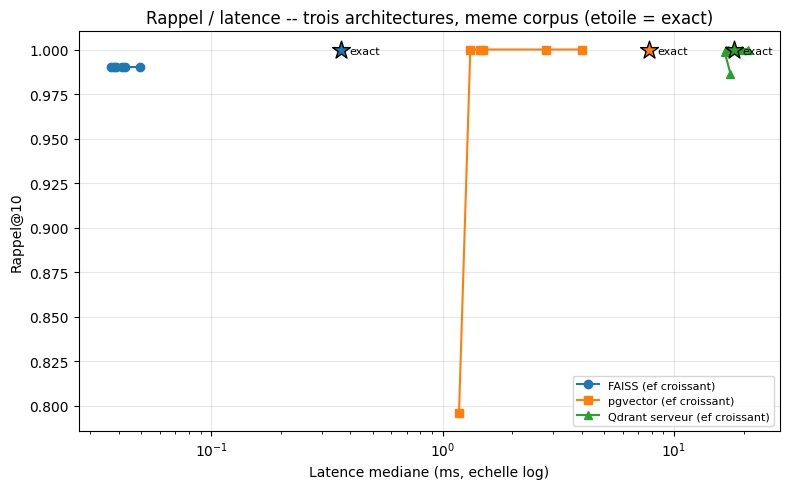

In [10]:
# Graphique signature : rappel contre latence mediane, trois moteurs sur un meme plan
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
series = [("FAISS", faiss_results, "o", "tab:blue"),
          ("pgvector", pg_results, "s", "tab:orange"),
          ("Qdrant serveur", qdrant_server_results, "^", "tab:green")]
for name, rows, marker, color in series:
    if not rows:
        continue
    ex = next(r for r in rows if "exact" in r["mode"])
    approx = [r for r in rows if "ef=" in r["mode"]]
    ax.plot([r["latence_med_ms"] for r in approx], [r["recall"] for r in approx],
            marker=marker, color=color, label=f"{name} (ef croissant)")
    ax.scatter([ex["latence_med_ms"]], [ex["recall"]], marker="*", s=180, color=color,
               edgecolor="black", zorder=5)
    ax.annotate("exact", (ex["latence_med_ms"], ex["recall"]),
                textcoords="offset points", xytext=(6, -3), fontsize=8)
ax.set_xlabel("Latence mediane (ms, echelle log)")
ax.set_ylabel("Rappel@10")
ax.set_xscale("log")
ax.set_title("Rappel / latence -- trois architectures, meme corpus (etoile = exact)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Lecture du graphique : trois courbes, une lecture

En abscisse log, les trois familles s'étalent par ordre d'architecture : l'appel de fonction à
gauche, l'aller-retour SQL et l'appel HTTP à droite. En ordonnée, tout le monde
rejoint le rappel exact — l'axe vertical ne sépare pas les moteurs, **l'axe horizontal les
sépare**. C'est la leçon : à qualité égale (le rappel se règle par ef), le choix d'architecture
se paie en latence et en services rendus (métadonnées, transactions, disque), pas en qualité de
recherche.

## 7. Exercices

Les exercices laissent la main : chacun étend une mesure du carnet. Les stubs s'exécutent sans
erreur (ils affichent leur rôle) — à vous de les compléter.

In [11]:
# Exercice 1 -- FAISS : le parametre m du graphe HNSW
# Contexte : toutes les mesures ci-dessus utilisent m=16. Le graphe (ses aretes) est le prix
# structurel du HNSW : m plus grand = meilleur rappel a ef egal, mais index plus lourd.
# TODO etudiant : pour m dans (8, 16, 32), construire IndexHNSWFlat (efConstruction=100),
# mesurer (a) le rappel@10 a ef=32, (b) la taille du fichier serialise, et retourner la table.
# Indice : reutiliser la boucle de bench_faiss et faiss.write_index comme en section 2.
def effet_m(m_values=(8, 16, 32), ef=32):
    # TODO etudiant
    print("Exercice a completer : rappel et empreinte de l'index en fonction de m")
    return None

effet_m()

Exercice a completer : rappel et empreinte de l'index en fonction de m


In [12]:
# Exercice 2 -- pgvector : le plancher d'ef_search
# Contexte : la section 3 balaye ef_search mais n'exploite pas le bas de la rampe.
# TODO etudiant : pour ef_search dans (4, 8, 16), mesurer le rappel@10 comme au banc,
# puis retourner le plus petit ef_search dont le rappel >= 0.95 (ou None s'il n'existe pas).
# Indice : SET hnsw.ef_search = ... puis la meme boucle de requetes qu'en section 3.
def plancher_ef_search(cible=0.95, bas=(4, 8, 16)):
    # TODO etudiant
    print("Exercice a completer : plus petit ef_search tenant le rappel cible")
    return None

plancher_ef_search()

Exercice a completer : plus petit ef_search tenant le rappel cible


In [13]:
# Exercice 3 -- FAISS filtre : le sur-tir minimal sans requete incomplete
# Contexte : la section 6 montre la cassure du post-filtre (sur-tir 50 -> requetes incompletes).
# TODO etudiant : balayer sur_tir dans (50, 100, 200, 400) et retourner la plus petite valeur
# pour laquelle AUCUNE des 200 requetes ne rend moins de k resultats filtres.
# Indice : compter len(got) < K comme en section 6, et raisonner sur la selectivite (~10 %).
def sur_tir_minimal(sur_tirs=(50, 100, 200, 400)):
    # TODO etudiant
    print("Exercice a completer : sur-tir minimal garantissant k resultats filtres")
    return None

sur_tir_minimal()

Exercice a completer : sur-tir minimal garantissant k resultats filtres


## Conclusion : ce que chaque moteur enseigne

**FAISS** enseigne le prix d'un appel : la recherche la plus rapide des trois, contre le contrat
le plus pauvre — pas de métadonnées, pas de persistance, pas de serveur ; le filtrage devient un
post-filtre à la main avec son piège de requêtes incomplètes. **pgvector** enseigne le prix d'une
base : chaque question est un SQL, plus lent à l'unité, mais le prédicat vit dans le plan (le
EXPLAIN le prouve) et les vecteurs héritent transactions, rôles, sauvegardes. **Qdrant** enseigne
le compromis dédié : recherche vectorielle avec payload intégré, filtrage pendant la traversée
du graphe, servi en conteneur comme en production.

Le verdict n'est pas un classement : à corpus et questions égales, **le rappel se règle (même
bouton sous trois noms, ef), la latence se choisit (architecture), le filtrage se négocie (où
vit le prédicat)**. C'est la grille de lecture à emporter pour choisir un stockage RAG.

**Continuer le parcours** : la suite bascule vers l'outillage au-dessus du stockage —
[06 — Kernel Memory in-process](06-KernelMemory-InProcess.ipynb).

### Mode dégradé : le filet de sécurité

Si Docker ou un moteur manque au moment de l'exécution, les sections correspondantes sautent avec
un message visible et la table finale ne liste que les moteurs réellement mesurés — jamais une
valeur fabriquée. Pour rejouer complet, provisionner les deux conteneurs puis réexécuter le
carnet de bout en bout :

```
docker run -d --rm --name rag05c_pgvector -p 5433:5432 \
    -e POSTGRES_PASSWORD=rag05c -e POSTGRES_DB=rag05c pgvector/pgvector:pg17
docker run -d --rm --name qdrant_rag05c -p 6333:6333 \
    -v qdrant_rag05c_data:/qdrant/storage qdrant/qdrant:latest
```